<h1 style="text-align: center; color: white; background-color: #1e86cc; border-radius: 30px; padding: 10px;">COSC3068 - Deep Learning</h1>
<h2 style="text-align: center;">Project 1: Letter Classification</h2>
<h3 style="text-align: center;">Author: Nguyen Gia Khang</h3>
<hr />

> I declare that this submission is my own work. I have acknowledged all sources of code, pretrained models, and other materials, and disclosed any use of AI tools in accordance with the course requirements.

## Import libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)


# I. Objective and Approach

This project is a nine-class image classification task involving grayscale patterns that resemble normalised two-dimensional Fourier spectra. The images show centred bright regions, rings, and streaks. The provided dataset contains **30,000** labelled, single-channel images, each measuring **32x32** pixels. Pixel values are represented as floating-point numbers between 0 and 1, and each image has one label in `{a, b, c, d, e, f, g, h, k}`. The task is to use the labelled images to identify the pattern class of a new image and return one of the nine permitted labels. The final classifier will be evaluated on a separate, unseen dataset with the same image format and label set.

# II. Dataset Inspection

### 1. Dataset loading and structure


The given dataset contains 30,000 labelled images. Each image has 32 by 32 pixels and is stored as `float32`; the labels are single-character strings representing nine letter classes: `{a, b, c, d, e, f, g, h, k}`.


In [2]:
with np.load("student_dataset.npz") as data:
    archive_keys = data.files
    images = data["images"]
    labels = data["labels"]

class_names, class_counts = np.unique(labels, return_counts=True)

print("Archive keys:", archive_keys)
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Classes:", ", ".join(class_names))


Archive keys: ['images', 'labels']
Images: (30000, 32, 32) float32
Labels: (30000,) <U1
Classes: a, b, c, d, e, f, g, h, k


### 2. Pixel values


The observed pixel values span 0 to 1, and every image value falls within the range specified for the dataset.


In [3]:
pixel_min = float(np.min(images))
pixel_max = float(np.max(images))
within_expected_range = bool(np.all((images >= 0) & (images <= 1)))

print(f"Minimum pixel value: {pixel_min:.3f}")
print(f"Maximum pixel value: {pixel_max:.3f}")
print("All pixels within [0, 1]:", within_expected_range)


Minimum pixel value: 0.000
Maximum pixel value: 1.000
All pixels within [0, 1]: True


### 3. Example images


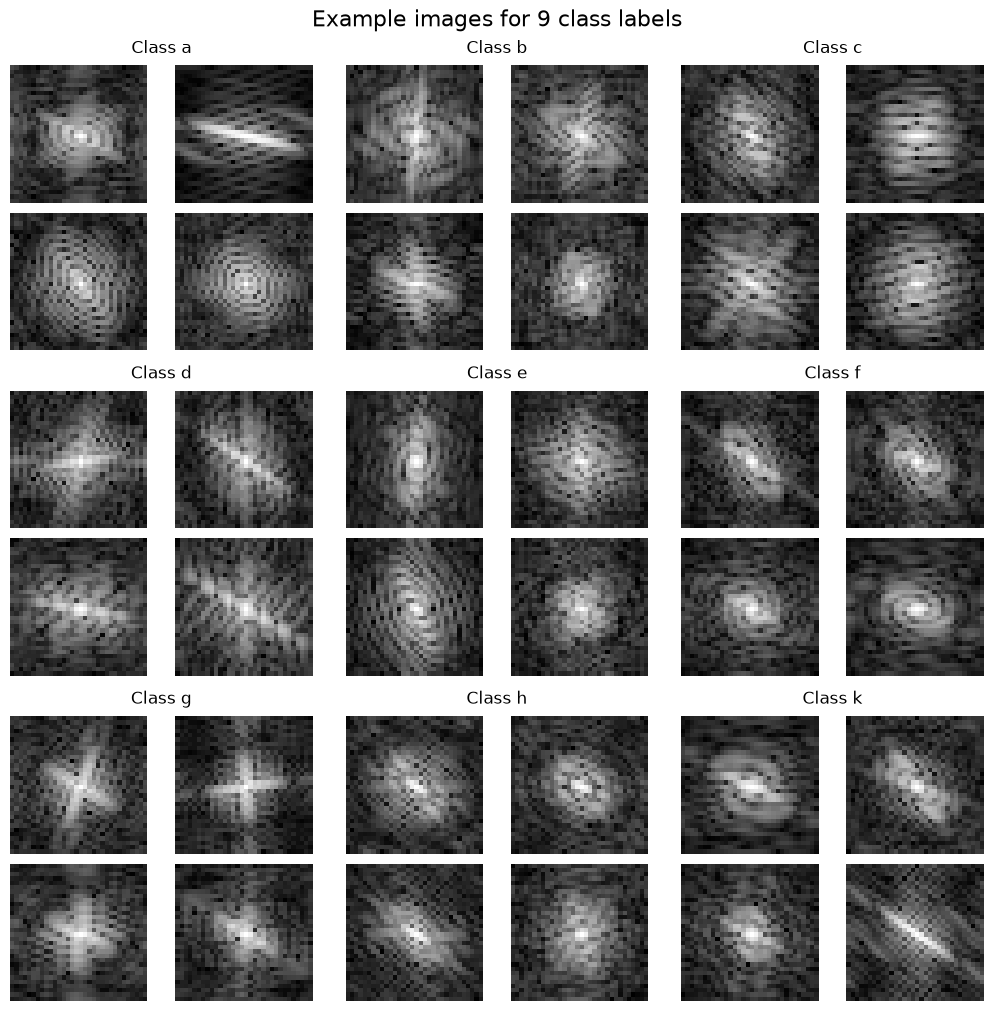

In [4]:
rng = np.random.default_rng(SEED)
fig = plt.figure(figsize=(10, 10), layout="constrained")
class_sections = fig.subfigures(3, 3)
fig.suptitle("Example images for 9 class labels", fontsize=16)

for section, label in zip(class_sections.flat, class_names):
    candidate_indices = np.flatnonzero(labels == label)
    selected_indices = rng.choice(candidate_indices, size=4, replace=False)
    section.suptitle(f"Class {label}", fontsize=12)
    axes = section.subplots(2, 2)
    for ax, image_index in zip(axes.flat, selected_indices):
        ax.imshow(images[image_index], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

plt.show()


### 4. Class distribution


The class counts range from **3,066** images for `e` **(10.22%)** to **3,492** images for `g` **(11.64%)**. All nine classes are represented at similar frequencies **(≈10 - 12%)**, so the dataset has no substantial class imbalance.

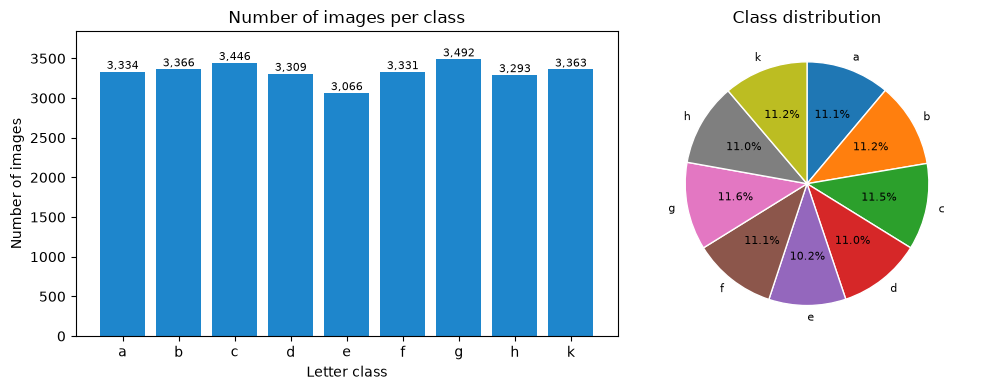

In [5]:
fig, (ax_bar, ax_pie) = plt.subplots(
    1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax_bar.bar(class_names, class_counts, color="#1e86cc")
ax_bar.set_xlabel("Letter class")
ax_bar.set_ylabel("Number of images")
ax_bar.set_title("Number of images per class")
ax_bar.set_ylim(0, max(class_counts) * 1.1)
for label, count in zip(class_names, class_counts):
    ax_bar.text(label, count, f"{count:,}", ha="center", va="bottom", fontsize=8)

ax_pie.pie(
    class_counts,
    labels=class_names,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
    textprops={"fontsize": 8},
)
ax_pie.set_title("Class distribution")
ax_pie.axis("equal")

fig.tight_layout()
plt.show()


### 5. Exact duplicate images

All 30,000 images have distinct pixel arrays, so there are no exact duplicate groups or identical images with conflicting labels. This check does not detect near-duplicates or images that look similar after small changes.

In [6]:
flat_images = images.reshape(len(images), -1)
_, image_ids, copies_per_image = np.unique(flat_images, axis=0, return_inverse=True, return_counts=True)
duplicate_ids = np.flatnonzero(copies_per_image > 1)
conflicting_ids = [
    image_id for image_id in duplicate_ids
    if np.unique(labels[image_ids == image_id]).size > 1
]

print(f"Total images: {len(images)}")
print(f"Distinct images: {len(copies_per_image)}")
print(f"Exact duplicate groups: {len(duplicate_ids)}")
print(f"Groups with conflicting labels: {len(conflicting_ids)}")


Total images: 30000
Distinct images: 30000
Exact duplicate groups: 0
Groups with conflicting labels: 0


# III. Validation and Preprocessing

### 1. Data split and rationale

The **30,000** labelled images are split into **80%** training, **10%** validation, and **10%** local holdout sets using stratified sampling and seed **42**. The training set is used to update model weights, while the validation set guides early stopping and model weight selection. Because repeated model weight choices can indirectly favour the validation set, the local holdout provides a separate performance check after the final configuration is fixed since it is not involved in any model training processes.

Stratified sampling keeps each class at nearly the same proportion in the training, validation, and holdout sets. This avoids accidental shifts in class balance between splits, making validation and holdout accuracy more representative of the full dataset. It preserves the original class distribution rather than correcting any imbalance in it.

In [7]:
CLASS_NAMES = np.array(["a", "b", "c", "d", "e", "f", "g", "h", "k"])
label_to_index = {label: i for i, label in enumerate(CLASS_NAMES)}

# Labels are encoded to integer indices for model training and evaluation.
y = np.array([label_to_index[label] for label in labels], dtype=np.int32)

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    images, y, test_size=0.1, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=1 / 9, random_state=SEED, stratify=y_dev
)

print(f"Training: {len(X_train):,}; validation: {len(X_val):,}; holdout: {len(X_holdout):,}")
print(f"{'Class':<8}{'Train %':>10}{'Val %':>10}{'Holdout %':>12}")
for class_index, label in enumerate(CLASS_NAMES):
    train_pct = 100 * np.mean(y_train == class_index)
    val_pct = 100 * np.mean(y_val == class_index)
    holdout_pct = 100 * np.mean(y_holdout == class_index)
    print(f"{label:<8}{train_pct:>9.2f}%{val_pct:>9.2f}%{holdout_pct:>11.2f}%")


Training: 24,000; validation: 3,000; holdout: 3,000
Class      Train %     Val %   Holdout %
a           11.12%    11.10%      11.10%
b           11.22%    11.23%      11.23%
c           11.48%    11.50%      11.50%
d           11.03%    11.03%      11.03%
e           10.22%    10.23%      10.23%
f           11.10%    11.10%      11.10%
g           11.64%    11.63%      11.63%
h           10.98%    10.97%      10.97%
k           11.21%    11.20%      11.20%


### 2. Preprocessing

The split arrays are converted to `tf.data.Dataset` pipelines. Each image is cast to `float32` and expanded from `(32, 32)` to `(32, 32, 1)`; integer labels use the fixed nine-class mapping. Pixel values remain in `[0, 1]`. The training pipeline shuffles images with seed **42**, batches **128** images, and applies augmentation such as random rotation and translation to each batch. Validation and holdout pipelines use the same channel expansion and batching without shuffling or augmentation.

Parallel mapping with `AUTOTUNE` lets TensorFlow adjust the number of concurrent preprocessing operations, while prefetching can overlap data preparation with model execution. Batching limits the number of images processed by the model at once. The NumPy arrays remain in RAM, and shuffle and prefetch buffers also use memory; the training shuffle buffer can hold the full training split. This pipeline does not explicitly cache the dataset. Augmentation is applied as training batches are consumed, allowing transformations to vary across epochs. Use `train_ds` for training and `val_ds` for validation; reserve `holdout_ds` for the final evaluation.

In [8]:
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomTranslation(0.08, 0.08, seed=SEED),
], name="data_augmentation")

def prepare_image(image, label):
    image = tf.expand_dims(tf.cast(image, tf.float32), axis=-1)
    return image, tf.cast(label, tf.int32)

def make_dataset(X, y, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((X, y))
    dataset = dataset.map(prepare_image, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.shuffle(len(X), seed=SEED)
    dataset = dataset.batch(BATCH_SIZE)
    if training:
        # Apply random augmentation to training batches as they are consumed.
        dataset = dataset.map(
            lambda batch, targets: (data_augmentation(batch, training=True), targets),
            num_parallel_calls=AUTOTUNE,
        )
    return dataset.prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
holdout_ds = make_dataset(X_holdout, y_holdout)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Holdout batches:", tf.data.experimental.cardinality(holdout_ds).numpy())



Training batches: 188
Validation batches: 24
Holdout batches: 24


### 3. Leakage prevention

To prevent leakage, the original images are split before augmentation or any **data-dependent** preprocessing steps. If augmented copies are created first and then split, versions of the same source image could appear in both training and validation or holdout sets, inflating measured accuracy. Only training images and labels update model weights, and random augmentation is applied only in the training dataset pipeline; validation and holdout images remain unaltered. Validation data guides early stopping and model weight selection, so its results are not treated as an independent final score. Prediction results are evaluated on the holdout set once after the final model configuration is fixed.

# IV. Model Architecture

### 1. Multilayer Perceptron (MLP)

The multilayer perceptron (MLP) **[1]** is the dense baseline for this nine-class task. The preprocessed ```(32, 32, 1)``` input is flattened into 1,024 values, followed by dense layers with 256 and 128 ReLU units, each with dropout at 0.30, and a nine-unit linear output producing logits. The model summary reports **296,457 trainable parameters**. Dropout is included as a regularisation choice to prevent overfitting.

This baseline tests how well a model using fully connected layers can classify the supplied pixel values. Flattening retains the pixels but does not explicitly encode their two-dimensional neighbourhoods; the first dense layer alone has 262,400 parameters. Comparing this baseline with the custom CNN will test whether spatial weight sharing is useful for these patterns. Its validation performance and the effect of dropout remain to be measured.

In [9]:
mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(9),
], name="mlp")


In [10]:
mlp_model.summary()


Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,457 (1.13 MB)

 Trainable params: 296,457 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

### 2. Custom CNN

The custom CNN receives preprocessed images of shape ```(32, 32, 1) ```and uses three 3 × 3 convolution layers with 32, 64, and 128 ReLU filters. Two 2 × 2 max-pooling layers reduce the spatial dimensions to 8 × 8; global average pooling, dropout at 0.25, and a nine-unit linear layer producing logits form the classifier. Its summary reports **93,833 trainable parameters**.

The convolution layers share weights across positions and can learn local features such as edges, rings, and streaks. Global average pooling reduces the size of the classifier, yielding fewer parameters than the MLP baseline. The pooling operations may discard fine spatial information; therefore, both validation accuracy and measured inference time are needed to assess the efficiency–performance trade-off.

In [11]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 1)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(9),
], name="custom_cnn")


In [12]:
cnn_model.summary()


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,833 (366.54 KB)

 Trainable params: 93,833 (366.54 KB)

 Non-trainable params: 0 (0.00 B)

### 3. ResNet18

The **ResNet18** experiment is trained from scratch and adapts the original residual design **[2]** for small grayscale images. A 3 × 3 stride-1 stem is followed by four stages with two basic residual blocks each, using 64, 128, 256, and 512 filters. Each block contains two 3 × 3 convolutions with batch normalisation, and a shortcut adds the block input to its output. The first block in stages 2–4 downsamples and uses a 1 × 1 projection to match dimensions. Global average pooling and a nine-unit linear layer producing logits complete the model.

The adapted stem omits the original initial max-pooling layer to retain more spatial detail from the 32 × 32 input. Residual shortcuts are intended to make a deeper network easier to optimise **[2]**, allowing a comparison of depth against the compact CNN. The summary reports **11,181,897 total parameters**, of which **11,172,297 are trainable** and **9,600 are batch-normalisation moving statistics**. This capacity may improve feature learning but increases the model's size; any accuracy gain and inference cost must be measured.

In [13]:
def residual_block(x, filters, stride, name):
    shortcut = x
    x = tf.keras.layers.Conv2D(
        filters, 3, strides=stride, padding="same", use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = tf.keras.layers.ReLU(name=f"{name}_relu1")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(x)
    x = tf.keras.layers.BatchNormalization(name=f"{name}_bn2")(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, 1, strides=stride, use_bias=False,
            name=f"{name}_projection"
        )(shortcut)
        shortcut = tf.keras.layers.BatchNormalization(
            name=f"{name}_projection_bn"
        )(shortcut)

    x = tf.keras.layers.Add(name=f"{name}_add")([x, shortcut])
    return tf.keras.layers.ReLU(name=f"{name}_out")(x)

inputs = tf.keras.layers.Input(shape=(32, 32, 1), name="image")

# A stride-1 stem preserves detail in 32 x 32 inputs.
x = tf.keras.layers.Conv2D(64, 3, padding="same", use_bias=False, name="stem_conv")(inputs)
x = tf.keras.layers.BatchNormalization(name="stem_bn")(x)
x = tf.keras.layers.ReLU(name="stem_relu")(x)

for stage, filters in enumerate((64, 128, 256, 512), start=1):
    for block in range(1, 3):
        stride = 2 if stage > 1 and block == 1 else 1
        x = residual_block(x, filters, stride, f"stage{stage}_block{block}")

x = tf.keras.layers.GlobalAveragePooling2D()(x)
outputs = tf.keras.layers.Dense(9)(x)
resnet18_model = tf.keras.Model(inputs, outputs, name="resnet18")


In [14]:
resnet18_model.summary(line_length=110, positions=[0.3, 0.5, 0.65, 1.0])


Model: "resnet18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape        ┃      Param # ┃ Connected to                         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)             │ (None, 32, 32, 1)   │            0 │ -                                    │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stem_conv (Conv2D)             │ (None, 32, 32, 64)  │          576 │ image[0][0]                          │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stem_bn (BatchNormalization)   │ (None, 32, 32, 64)  │          256 │ stem_conv[0][0]                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stem_relu (ReLU)               │ (None, 32, 32, 64)  │            0 │ stem_bn[0][0]                        │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_conv1 (Conv2D)   │ (None, 32, 32, 64)  │       36,864 │ stem_relu[0][0]                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_bn1              │ (None, 32, 32, 64)  │          256 │ stage1_block1_conv1[0][0]            │
│ (BatchNormalization)           │                     │              │                                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_relu1 (ReLU)     │ (None, 32, 32, 64)  │            0 │ stage1_block1_bn1[0][0]              │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_conv2 (Conv2D)   │ (None, 32, 32, 64)  │       36,864 │ stage1_block1_relu1[0][0]            │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_bn2              │ (None, 32, 32, 64)  │          256 │ stage1_block1_conv2[0][0]            │
│ (BatchNormalization)           │                     │              │                                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_add (Add)        │ (None, 32, 32, 64)  │            0 │ stage1_block1_bn2[0][0],             │
│                                │                     │              │ stem_relu[0][0]                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block1_out (ReLU)       │ (None, 32, 32, 64)  │            0 │ stage1_block1_add[0][0]              │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block2_conv1 (Conv2D)   │ (None, 32, 32, 64)  │       36,864 │ stage1_block1_out[0][0]              │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block2_bn1              │ (None, 32, 32, 64)  │          256 │ stage1_block2_conv1[0][0]            │
│ (BatchNormalization)           │                     │              │                                      │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block2_relu1 (ReLU)     │ (None, 32, 32, 64)  │            0 │ stage1_block2_bn1[0][0]              │
├────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────────────────┤
│ stage1_block2_conv2 (Conv2D)   │ (None, 32, 32, 64)  │       36,864 │ stage1_block2_relu1[0][0]            │
├───

 Total params: 11,181,897 (42.66 MB)

 Trainable params: 11,172,297 (42.62 MB)

 Non-trainable params: 9,600 (37.50 KB)

### 4. MobileNetV2 — ImageNet pretrained

The transfer-learning model uses **Keras MobileNetV2** with **ImageNet** weights and its original classifier removed **[3]**, **[4]**. The preprocessed ```(32, 32, 1)``` input is resized to ```(64, 64, 1)```, repeated across three channels, and scaled from ```[0, 1]``` to ```[-1, 1]``` for the pretrained base. Its 1,280 output feature maps are globally averaged, followed by dropout at 0.20 and a new nine-unit linear classifier producing logits.

The base is initially frozen, leaving **11,529 trainable parameters** in the new classifier out of **2,269,513 total**. This experiment tests whether pretrained features transfer to the supplied patterns; **ImageNet** photographs and these grayscale images differ, so an improvement is not assumed. A later fine-tuning stage can unfreeze selected layers at a lower learning rate while keeping batch-normalisation statistics fixed **[5]**. Resizing adds computation without recovering original image detail, and the full base is still used for inference even when frozen. Both accuracy and inference time therefore need comparison with the models trained from scratch.

In [15]:
# Downloads ImageNet weights on the first run; later runs use the Keras cache.
# At 64 x 64, Keras uses the convolutional weights from the 224 x 224 checkpoint.
mobilenetv2_base = tf.keras.applications.MobileNetV2(
    input_shape=(64, 64, 3),
    alpha=1.0,
    include_top=False,
    weights="imagenet",
)
# First train the classifier; unfreeze selected base layers later for fine-tuning.
mobilenetv2_base.trainable = False

mobile_inputs = tf.keras.layers.Input(shape=(32, 32, 1), name="image")
x = tf.keras.layers.Resizing(64, 64, interpolation="bilinear")(mobile_inputs)
x = tf.keras.layers.Concatenate(axis=-1)([x, x, x])
x = tf.keras.layers.Rescaling(scale=2.0, offset=-1.0)(x)

# Keep batch-normalisation moving statistics fixed, including during fine-tuning.
x = mobilenetv2_base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.20)(x)
mobile_outputs = tf.keras.layers.Dense(9)(x)
mobilenetv2_model = tf.keras.Model(
    mobile_inputs, mobile_outputs, name="mobilenetv2_transfer"
)


C:\Users\NguyenKhang\AppData\Local\Temp\ipykernel_160\398722281.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenetv2_base = tf.keras.applications.MobileNetV2(


In [16]:
mobilenetv2_model.summary(line_length=100, positions=[0.3, 0.5, 0.65, 1.0])


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape      ┃     Param # ┃ Connected to                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)          │ (None, 32, 32, 1) │           0 │ -                                │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ resizing (Resizing)         │ (None, 64, 64, 1) │           0 │ image[0][0]                      │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ concatenate (Concatenate)   │ (None, 64, 64, 3) │           0 │ resizing[0][0], resizing[0][0],  │
│                             │                   │             │ resizing[0][0]                   │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ rescaling (Rescaling)       │ (None, 64, 64, 3) │           0 │ concatenate[0][0]                │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ mobilenetv2_1.00_224        │ (None, 2, 2,      │   2,257,984 │ rescaling[0][0]                  │
│ (Functional)                │ 1280)             │             │                                  │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ global_average_pooling2d_2  │ (None, 1280)      │           0 │ mobilenetv2_1.00_224[0][0]       │
│ (GlobalAveragePooling2D)    │                   │             │                                  │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ dropout_3 (Dropout)         │ (None, 1280)      │           0 │ global_average_pooling2d_2[0][0] │
├─────────────────────────────┼───────────────────┼─────────────┼──────────────────────────────────┤
│ dense_5 (Dense)             │ (None, 9)         │      11,529 │ dropout_3[0][0]                  │
└─────────────────────────────┴───────────────────┴─────────────┴──────────────────────────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# V. Training Methodology

### 1. Activation functions

**ReLU** introduces nonlinearity in the **MLP**, custom **CNN** and **ResNet18**. It is inexpensive to compute and has derivative 1 for positive inputs, although units with negative inputs can become inactive **[6]**. **MobileNetV2** retains its pretrained activations, including **ReLU6** in expanded representations and linear bottlenecks **[3]**.

$$\operatorname{ReLU}(z)=\max(0,z),\qquad \operatorname{ReLU6}(z)=\min(6,\max(0,z)).$$

Each classifier outputs nine unnormalised scores called logits. Softmax converts logits $z_k$ to non-negative probabilities that sum to one **[7]**, matching the task's single label per image. It is applied when probabilities are needed; the predicted class can be selected directly using the largest logit, since softmax preserves their order. Softmax alone does not guarantee calibrated confidence.

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{n}e^{z_j}},\qquad \hat y=\arg\max_k p_k.$$

ReLU is implemented in **Section IV**; the example below illustrates ReLU and the softmax conversion from logits.

In [17]:
example_scores = tf.constant([[-1.0, 0.0, 1.0, 2.0, 0.5, -0.5, 0.2, 0.1, -0.2]])
print("ReLU:", tf.nn.relu(example_scores).numpy())
example_probabilities = tf.nn.softmax(example_scores, axis=-1)
print("Softmax probabilities:", example_probabilities.numpy())
print("Probability sum:", tf.reduce_sum(example_probabilities).numpy())


ReLU: [[0.  0.  1.  2.  0.5 0.  0.2 0.1 0. ]]
Softmax probabilities: [[0.02179926 0.05925654 0.161076   0.4378499  0.09769752 0.03594091
  0.07237611 0.06548861 0.04851515]]
Probability sum: 1.0


### 2. Loss function

**Sparse categorical cross-entropy** is used because each image has one integer target from 0 to 8. For $N$ examples, it is the mean negative log probability assigned to the correct class, equivalent to minimising the categorical negative log-likelihood **[7]**. The sparse representation avoids one-hot label arrays without changing the underlying objective.

$$\mathcal{L}_{\mathrm{CE}}=-\frac{1}{N}\sum_{i=1}^{N}\log p_{i,y_i}.$$

This penalises confident incorrect predictions more strongly. The classifiers output raw logits, so `from_logits=True` lets the loss compute softmax cross-entropy directly using a numerically stable formulation. This avoids manually taking logarithms of potentially tiny softmax probabilities. Both logits and probability formulations can be valid when their settings match; this choice does not guarantee better accuracy. The classes are fairly balanced, so the initial configuration does not apply class weights. Suspected label errors remain a limitation, since cross-entropy can strongly penalise a confident prediction against an incorrect target.

In [18]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
example_target = tf.constant([3], dtype=tf.int32)
print("Example cross-entropy:", loss_fn(example_target, example_scores).numpy())


Example cross-entropy: 0.8258791


### 3. Optimiser

**AdamW** combines Adam's moving estimates of the gradient and squared gradient with decoupled weight decay **[8]**. A simplified update, using bias-corrected moments $\hat m_t$ and $\hat v_t$, is

$$\theta_{t+1}=\theta_t-\eta_t(\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta_t).$$

Here $\eta_t$ is the learning rate and $\lambda$ is weight decay. The decay is applied separately from the adaptive gradient update, so it differs from simply adding an L2 penalty to Adam's loss **[8]**. Initial settings are $\eta=10^{-3}$ and $\lambda=10^{-4}$, with biases and batch-normalisation scale and offset excluded from decay. Each model receives a fresh optimiser instance. These are starting choices to compare using validation learning curves.

For **MobileNetV2**, first train the classifier with the base frozen. After that stage converges, the helper below enables fine-tuning of the final 20 base layers, freezes batch-normalisation layers, and recompiles with a fresh optimiser at $\eta=10^{-5}$. Defining the helper does not unfreeze or train the base; call it only after classifier training.

In [19]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
FINE_TUNE_LEARNING_RATE = 1e-5

def make_optimizer(learning_rate=LEARNING_RATE):
    optimizer = tf.keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=WEIGHT_DECAY)
    optimizer.exclude_from_weight_decay(var_names=["bias", "beta", "gamma"])
    return optimizer

def compile_classifier(model, learning_rate=LEARNING_RATE):
    model.compile(
        optimizer=make_optimizer(learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

for classifier in (mlp_model, cnn_model, resnet18_model, mobilenetv2_model):
    compile_classifier(classifier)

def configure_mobilenet_fine_tuning():
    # Call only after training the frozen-base classifier.
    mobilenetv2_base.trainable = True
    for layer in mobilenetv2_base.layers[:-20]:
        layer.trainable = False
    for layer in mobilenetv2_base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    compile_classifier(mobilenetv2_model, FINE_TUNE_LEARNING_RATE)


### 4. Regularisation

**Dropout** randomly sets a proportion of activations to zero during training, reducing dependence on particular units and helping limit overfitting **[9]**. The **MLP** uses a dropout rate of **0.30**, the custom **CNN** **0.25**, and the **MobileNetV2** classifier **0.20**, as defined in **Section IV**. **Dropout** is inactive during evaluation and prediction. These rates are initial choices whose effect should be assessed using validation results.

**Early stopping** ends training when a monitored validation metric stops improving, limiting further fitting to the training data **[10]**. The callback below monitors validation loss with a patience of five epochs and restores the weights from the epoch with the lowest validation loss. This provides a stopping rule within the 30-epoch budget. A fresh callback is used for each training run, and the local holdout does not influence the stopping decision.

In [20]:
MAX_EPOCHS = 30

# Pass callbacks=make_callbacks(model_name) and epochs=MAX_EPOCHS to each model.fit() call.

def make_callbacks(model_name):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=5,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    return callbacks


# VI. Experiments and Results

# VII. Evaluation and Error Analysis

# VIII. Reflection and Reproducibility

# IX. Sources and Acknowledgements

**[1]** M.-C. Popescu, V. E. Balas, L. Perescu-Popescu, and N. E. Mastorakis, "Multilayer perceptron and neural networks," *WSEAS Trans. Circuits Syst.*, vol. 8, no. 7, pp. 579–588, Jul. 2009, doi: 10.5555/1639537.1639542.

**[2]** K. He, X. Zhang, S. Ren and J. Sun, “Deep residual learning for image recognition,” arXiv preprint arXiv:1512.03385, 2015, doi: 10.48550/arXiv.1512.03385.

**[3]** M. Sandler, A. Howard, M. Zhu, A. Zhmoginov, and L.-C. Chen, "MobileNetV2: inverted residuals and linear bottlenecks," arXiv preprint arXiv:1801.04381, 2018, doi: 10.48550/arXiv.1801.04381.

**[4]** Keras, "MobileNet, MobileNetV2, and MobileNetV3." Accessed: Nov. 20, 2026. [Online]. Available: https://keras.io/api/applications/mobilenet/mobilenet_models/

**[5]** TensorFlow, “Transfer learning & fine-tuning.” Accessed: Nov. 20, 2026. [Online]. Available: https://www.tensorflow.org/guide/keras/transfer_learning

**[6]** S. R. Dubey, S. K. Singh, and B. B. Chaudhuri, "Activation functions in deep learning: a comprehensive survey and benchmark," *Neurocomputing*, vol. 503, pp. 92-108, Sep. 2022, doi: 10.1016/j.neucom.2022.06.111.

**[7]** J. Terven, D.-M. Cordova-Esparza, J.-A. Romero-González, A. Ramírez-Pedraza, and E. A. Chávez-Urbiola, "Loss Functions and Metrics in Deep Learning," *Artif. Intell. Rev.*, vol. 58, no. 7, Art. no. 195, 2025, doi: 10.1007/s10462-025-11198-7.

**[8]** I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," arXiv preprint arXiv:1711.05101, 2017, doi: 10.48550/arXiv.1711.05101.

**[9]** N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov, "Dropout: a simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, pp. 1929-1958, 2014. [Online]. Available: https://jmlr.org/papers/v15/srivastava14a.html

**[10]** L. Prechelt, "Automatic early stopping using cross validation: quantifying the criteria," *Neural Networks*, vol. 11, no. 4, pp. 761-767, 1998, doi: 10.1016/S0893-6080(98)00010-0.
